# Hito 4 — Clustering exploratorio (K-Means) sobre las caracteristicas acusticas

**Proyecto 1 de Innovacion Tecnologica — Maestria en Inteligencia Artificial Aplicada (MIAA)**
**Universidad Icesi · Cali, Colombia**
**Responsables del Hito 4:** Juan Fernando Gutierrez · Miguel Angel Paz
**Equipo:** Juan Fernando Gutierrez · Miguel Angel Paz · Carlos Alberto Salamando · Veronica Serna

---

## Objetivo

Explorar, de forma **no supervisada**, si las 90 caracteristicas acusticas del Hito 3 agrupan los clips de 5 s
de forma consistente con las 16 especies reales del subconjunto Magdalena Medio — sin usar las etiquetas para
entrenar el agrupamiento, solo para evaluarlo despues. Ver metodologia completa en
[`docs/hito4_clustering_report.md`](../docs/hito4_clustering_report.md).

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.training.hito4_clustering import run_hito4_clustering

metrics = run_hito4_clustering()


=== Hito 4 — Clustering exploratorio (K-Means) sobre features acusticas ===

Clips usados (train+val, sin test): 17,893
Adjusted Rand Index (cluster vs especie real): 0.0315
Silhouette Score (muestra de 3000): 0.0206
Clips alineados con especie mayoritaria de su cluster: 3,787/17,893
SNR medio (alineados): 16.34 dB | SNR medio (no alineados): 14.65 dB
Spearman(distancia a centroide, snr_db) = 0.3483 (p=0.00e+00)
Spearman(distancia a centroide, inband_energy_ratio) = 0.2708 (p=2.86e-298)

Resultados guardados en: /sessions/rcw-018vtbaee1atikpxtnsuvoeq/mnt/Proyecto-1-MIAA/experiments/results/hito4_5/clustering


## Resultados numericos completos (JSON)

In [2]:
import json
print(json.dumps(metrics, indent=2, ensure_ascii=False))

{
  "status": "FULL_EXECUTION",
  "seed": 42,
  "n_clusters": 16,
  "n_clips_used": 17893,
  "feature_columns_used": 90,
  "adjusted_rand_index": 0.03147633132047255,
  "silhouette_score": 0.02061895038507205,
  "silhouette_sample_size": 3000,
  "pca_explained_variance_ratio": [
    0.259443084145518,
    0.059431659351148476,
    0.04778419617658517
  ],
  "n_clips_aligned_with_cluster_majority_species": 3787,
  "n_clips_total": 17893,
  "snr_db_mean_aligned": 16.33539028254555,
  "snr_db_mean_misaligned": 14.646221607826456,
  "spearman_dist_vs_snr_db": {
    "rho": 0.3482753069137078,
    "p_value": 0.0
  },
  "spearman_dist_vs_inband_energy_ratio": {
    "rho": 0.2708019278622894,
    "p_value": 2.8557872629338237e-298
  }
}


## Figura 1 — Proyeccion PCA 2D: cluster K-Means vs. especie real

clusters_2d.png


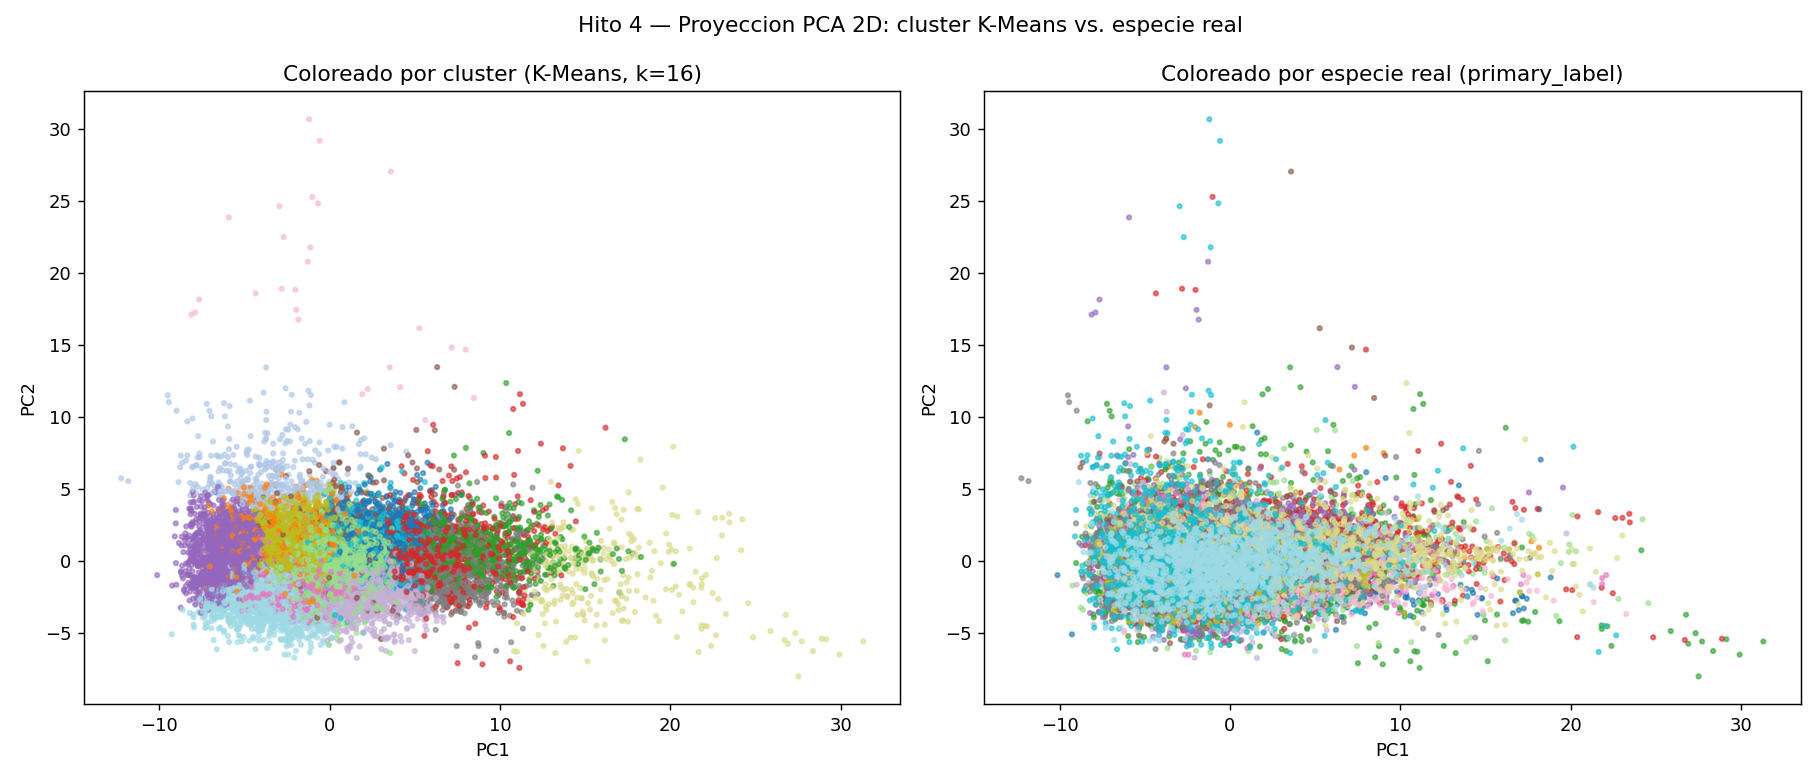

In [3]:
_fig1 = str(PROJECT_ROOT / "experiments" / "results" / "hito4_5" / "clustering" / "figures" / "clusters_2d.png")
print("clusters_2d.png")

## Figura 2 — Proyeccion PCA 3D: cluster K-Means vs. especie real

clusters_3d.png


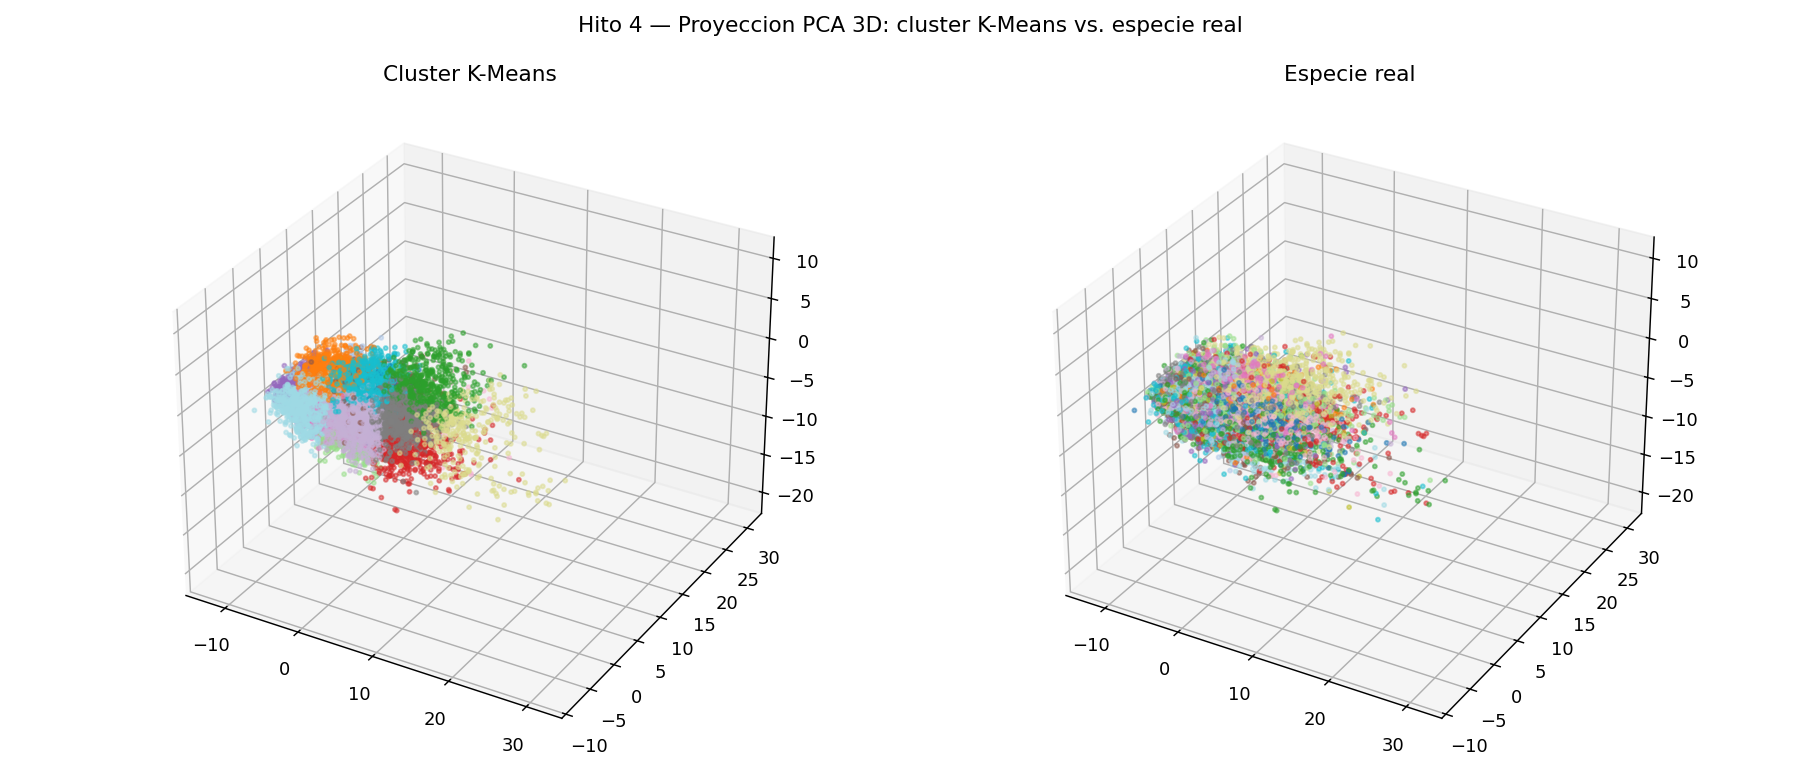

In [4]:
_fig1 = str(PROJECT_ROOT / "experiments" / "results" / "hito4_5" / "clustering" / "figures" / "clusters_3d.png")
print("clusters_3d.png")

## Figura 3 — Relacion entre agrupamiento y ruido de fondo (SNR)

clusters_vs_noise.png


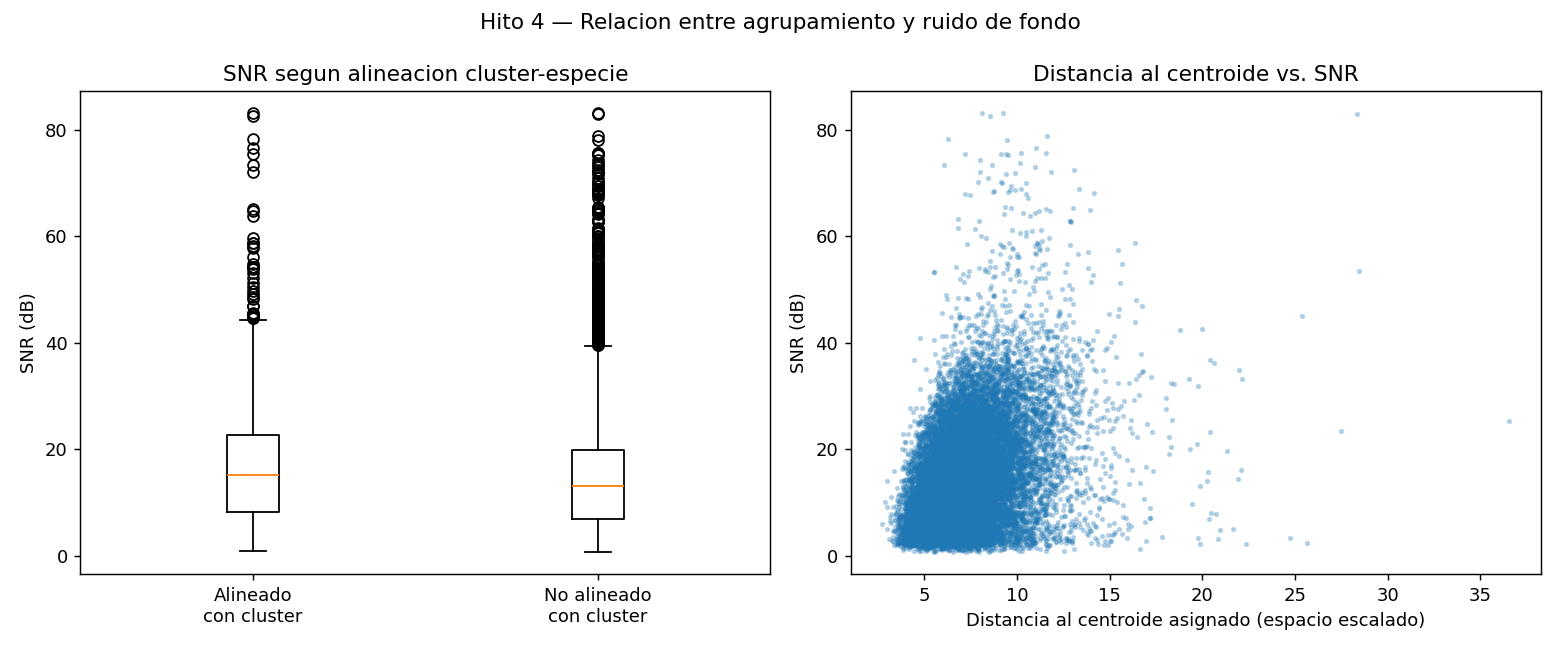

In [5]:
_fig1 = str(PROJECT_ROOT / "experiments" / "results" / "hito4_5" / "clustering" / "figures" / "clusters_vs_noise.png")
print("clusters_vs_noise.png")

## Conclusion

ARI y Silhouette muy bajos indican que K-Means sobre las features acusticas crudas no separa bien las 16
especies de forma no supervisada; sin embargo, la distancia al centroide correlaciona de forma significativa
con el SNR del clip, sugiriendo que parte de la dispersion observada proviene de calidad/ruido del audio y no
solo de similitud acustica entre especies. Esto no implica que las features sean inutiles para clasificacion
supervisada — ver [`hito5_baseline_svm_report.md`](../docs/hito5_baseline_svm_report.md).